# OB-GYN supply after *Dobbs*, replicated and extended to 2026

**A replication of Zhu et al. (JAMA Internal Medicine, 2025) on the monthly NPPES panel, then the same design with two more years.**

Zhu, Huntington, McConnell, Whelan, Aaron and Rodriguez ("Post-*Dobbs* decision changes in obstetrics and gynecology clinical workforce in states with abortion restrictions", *JAMA Intern Med* 185(5):598-600, 2025, doi:10.1001/jamainternmed.2024.8149) asked whether the supply of OB-GYN practitioners fell in the states that banned or near-banned abortion after the June 2022 *Dobbs* decision. They counted practitioners with an OB-GYN primary taxonomy in NPPES, by primary practice state, in the December files of 2018 to 2023 and the July 2024 file, divided by each state's female population aged 15 to 49, and compared the 12 most restrictive states with 14 states whose (lesser) restrictions did not change after *Dobbs*. The difference-in-differences estimate was -3.0 practitioners per 100,000 reproductive-age women, a 4.2 percent relative decline (P = .04). The authors named two limits: "a condensed follow-up period (2 years) and reliance on NPPES data, which can be delayed".

The study uses only public data, so it can be rebuilt exactly. This notebook

1. rebuilds the study's state-year panel from the export and reproduces its Table and its two sample sensitivity rows,
2. runs the sensitivity analyses the supplement describes but does not report (population weights, family physicians and nurse practitioners with an obstetric taxonomy, a primary care falsification test),
3. runs the same regression with the NPPES files published since: December 2024, December 2025 and July 2026, four years after *Dobbs* instead of two,
4. runs the paper's parallel-trends test with its estimate shown, the year-by-year estimates, and the monthly series that the December files sample.

The replication matches the paper to within a few tenths per 100,000. The extension makes the estimate larger, but the gap between the two groups of states was widening at the same pace before *Dobbs* as after it (sections 5 and 6).

Everything follows the paper's definitions, which are in its online supplement (eMethods, eTables 1 and 2). Where the supplement does not say, the notebook says what it used.

The tables are built in DuckDB SQL over the export; the regressions use `pyfixest`.

In [1]:
import os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import duckdb
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pyfixest as pf

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})

EXPORT = Path(os.environ.get("NPPES_EXPORT", "../../export")).resolve()
assert (EXPORT / "manifest.json").exists(), f"{EXPORT} is not a complete export: set NPPES_EXPORT"

# One view per export table. The views read Parquet lazily; nothing is copied.
con = duckdb.connect()
con.execute("SET VARIABLE export = ?", [str(EXPORT)])
con.execute("""
CREATE VIEW provider AS
SELECT * FROM read_parquet(getvariable('export') || '/parquet/provider/*/*.parquet', hive_partitioning = true);
CREATE VIEW provider_taxonomy AS
SELECT * FROM read_parquet(getvariable('export') || '/parquet/provider_taxonomy/*/*.parquet', hive_partitioning = true);
CREATE VIEW snapshots AS
SELECT * FROM read_csv(getvariable('export') || '/snapshots.csv');
""");

## 1. States, denominators and taxonomy codes

The paper's groups (eMethods) come from the Guttmacher Institute's legislation tracker as of July 2024. **Most restrictive** (12): Alabama, Arkansas, Idaho, Kentucky, Louisiana, Mississippi, Missouri, Oklahoma, South Dakota, Tennessee, Texas and West Virginia. **Comparison** (14): Delaware, Florida, Iowa, Kansas, Michigan, Montana, Nevada, New Hampshire, Pennsylvania, Rhode Island, Utah, Virginia, Wisconsin and Wyoming, states with restrictions before *Dobbs* that did not change their level after it. Indiana is left out because its law passed in 2024. The other 24 states and DC are not in the study.

The denominator is the female population aged 15 to 49 in the 2017-2021 American Community Survey 5-year estimates, table B01001, the sum of the ten female age groups from 15-17 to 45-49. [`data/states.csv`](data/states.csv) has it for every state, and the value the paper printed in its eTable 2 for the 26 study states.

In [2]:
con.execute("""
CREATE TABLE states AS
SELECT state, name, nullif(study_group, '') AS study_group,
       women_15_49::BIGINT AS women, nullif(etable2_women_15_49, '')::BIGINT AS etable2_women
FROM read_csv('data/states.csv', all_varchar = true);

CREATE TABLE taxonomy AS
SELECT code, code_set, name FROM read_csv('data/taxonomy.csv', all_varchar = true);
""")
con.sql("""
SELECT state, name, study_group, women AS acs_2017_2021, etable2_women AS etable2, round(etable2_women / women, 3) AS ratio
FROM states WHERE study_group IS NOT NULL AND etable2_women <> women ORDER BY name
""").df()

,state,name,study_group,acs_2017_2021,etable2,ratio
0,MS,Mississippi,restrictive,678137,1362830,2.010
1,MO,Missouri,restrictive,1362830,678137,0.498
2,NV,Nevada,control,695742,291844,0.419
3,NH,New Hampshire,control,291844,695742,2.384


eTable 2 matches the ACS exactly for 22 of the 26 states. In the other four, two alphabetical neighbours have swapped values: Mississippi is printed with Missouri's population and Missouri with Mississippi's, and the same for Nevada and New Hampshire. Section 2 shows that the regression used the correct values; the swap is in the printed table only.

The practitioners are individuals (entity type 1) whose **primary** taxonomy, the slot CMS flags as primary (`primary_taxonomy = 'Y'` in `provider_taxonomy`), is one of the eleven OB-GYN codes of eTable 1: nine obstetrics and gynecology physician codes, `176B00000X` midwife and `367A00000X` advanced practice midwife. A record with no taxonomy flagged primary has no primary taxonomy and is not counted. A practitioner counts in the state of their primary practice address on the file's date. Deactivated NPIs have no practice address on the file and drop out.

eTable 1 also lists the codes for two sensitivity samples. Family physicians (`207Q00000X`) count when a secondary taxonomy is one of the OB-GYN codes. Nurse practitioners count "with any primary or secondary taxonomy related to obstetrics", but eTable 1 lists no nurse practitioner codes; we use the three NUCC nurse practitioner codes that name obstetrics or women's health (`363LX0001X` obstetrics and gynecology, `363LP1700X` perinatal, `363LW0102X` women's health). The falsification sample is the seven primary care codes of eTable 1.

In [3]:
con.execute("""
CREATE TABLE study_versions AS      -- versions of individuals practising in a study state, with the samples each version is in
SELECT p.npi, p.practice_state AS state, p.effective_date, p.end_date,
       bool_or(t.primary_taxonomy = 'Y' AND x.code_set = 'obgyn') AS obgyn,
       bool_or(t.primary_taxonomy = 'Y' AND x.code_set = 'family_medicine')
           AND bool_or(t.primary_taxonomy IS DISTINCT FROM 'Y' AND x.code_set = 'obgyn') AS family_medicine_ob,
       bool_or(x.code_set = 'np_obstetric') AS np_obstetric,
       bool_or(t.primary_taxonomy = 'Y' AND x.code_set = 'primary_care') AS primary_care
FROM provider p
JOIN states s ON s.state = p.practice_state AND s.study_group IS NOT NULL
JOIN provider_taxonomy t ON t.npi = p.npi AND t.effective_date = p.effective_date
JOIN taxonomy x ON x.code = t.taxonomy_code          -- only the codes of some sample can make a version qualify
WHERE p.entity_type = '1'
GROUP BY ALL
HAVING obgyn OR family_medicine_ob OR np_obstetric OR primary_care;
""")
print("{:,} versions of {:,} individuals".format(*con.sql("SELECT count(*), count(DISTINCT npi) FROM study_versions").fetchone()))

1,011,632 versions of 258,734 individuals


## 2. The paper's panel, rebuilt

The paper's dates are the December file of each year 2018 to 2023 and the July 2024 file; the post-period starts with December 2022. The extension (section 4) uses every December file through 2025 and the July 2026 file. A state-year cell counts the versions that were current on the file's as-of date.

In [4]:
con.execute("""
CREATE TABLE panel_dates AS
SELECT 'paper' AS panel, year(as_of_date) AS year, as_of_date FROM snapshots
WHERE (month(as_of_date) = 12 AND year(as_of_date) BETWEEN 2018 AND 2023)
   OR (month(as_of_date) = 7 AND year(as_of_date) = 2024)
UNION ALL
SELECT 'extended', year(as_of_date), as_of_date FROM snapshots
WHERE (month(as_of_date) = 12 AND year(as_of_date) BETWEEN 2018 AND 2025)
   OR (month(as_of_date) = 7 AND year(as_of_date) = 2026);

CREATE TABLE state_year AS
SELECT d.panel, d.year, d.as_of_date, s.state, s.study_group, s.women,
       count(v.npi) FILTER (WHERE v.obgyn) AS obgyn,
       count(v.npi) FILTER (WHERE v.obgyn OR v.family_medicine_ob OR v.np_obstetric) AS obgyn_fm_np,
       count(v.npi) FILTER (WHERE v.primary_care) AS primary_care
FROM panel_dates d
CROSS JOIN states s
LEFT JOIN study_versions v ON v.state = s.state AND v.effective_date <= d.as_of_date
                          AND (v.end_date IS NULL OR v.end_date > d.as_of_date)
WHERE s.study_group IS NOT NULL
GROUP BY ALL;
""")
panel = con.table("state_year").df()
for col in ("obgyn", "obgyn_fm_np", "primary_care"):
    panel[col + "_rate"] = panel[col] / panel.women * 1e5
panel["restrictive"] = (panel.study_group == "restrictive").astype(int)
panel["post"] = (panel.year >= 2022).astype(int)
panel["did"] = panel.restrictive * panel.post
paper = panel[panel.panel == "paper"].copy()
extended = panel[panel.panel == "extended"].copy()
# one file per study year, or the regressions below silently change
assert con.sql("SELECT count(*) = count(DISTINCT (panel, year)) FROM panel_dates").fetchone()[0], "two files in one study month"
assert sorted(paper.year.unique()) == list(range(2018, 2025)), "a file of the paper's panel is missing from the export"
assert sorted(extended.year.unique()) == list(range(2018, 2027)), "a file of the extended panel is missing from the export"
print(paper.groupby("year").as_of_date.first().astype(str).to_dict())
(paper.pivot_table(index="year", columns="study_group", values="obgyn", aggfunc="sum")).astype(int)

{2018: '2018-12-09', 2019: '2019-12-19', 2020: '2020-12-13', 2021: '2021-12-12', 2022: '2022-12-11', 2023: '2023-12-10', 2024: '2024-07-07'}


study_group,control,restrictive
year,,
2018,14389,10874
2019,14890,11191
2020,15332,11456
2021,15769,11791
2022,16260,12149
2023,16768,12532
2024,17121,12709


The Table of the paper reports the mean and standard deviation of the state rates in each group and period, and the difference-in-differences estimate from a regression of the state rate on the treatment indicator with state and year fixed effects and standard errors clustered by state. The same regression here:

In [5]:
def did(data, outcome="obgyn_rate", weights=None):
    m = pf.feols(f"{outcome} ~ did | state + year", data=data, weights=weights, vcov={"CRV1": "state"})
    t = m.tidy().loc["did"]
    pre = data[(data.restrictive == 1) & (data.post == 0)]
    base = np.average(pre[outcome], weights=pre[weights] if weights else None)   # same weighting as the estimate
    return {"estimate": t["Estimate"], "ci_low": t["2.5%"], "ci_high": t["97.5%"], "p": t["Pr(>|t|)"],
            "percent": 100 * t["Estimate"] / base}

def group_means(data, outcome="obgyn_rate"):
    g = data.groupby(["study_group", "post"])[outcome].agg(["mean", "std"])
    return {f"{grp} {'post' if post else 'pre'}": f"{r['mean']:.1f} ({r['std']:.1f})" for (grp, post), r in g.iterrows()}

samples = {"All states": paper,
           "Without Texas": paper[paper.state != "TX"],
           "Without Texas and Wisconsin": paper[~paper.state.isin(["TX", "WI"])]}
ours = pd.DataFrame({k: {**group_means(d), **{k2: round(v, 2) for k2, v in did(d).items()}} for k, d in samples.items()}).T
published = pd.DataFrame({
    "All states": ["93.3 (20.3)", "71.5 (10.7)", "102.7 (22.3)", "77.8 (12.1)", -3.0, -5.9, -0.2, 0.04, -4.2],
    "Without Texas": ["93.3 (20.3)", "71.9 (11.1)", "102.7 (22.3)", "78.0 (12.6)", -3.2, -6.1, -0.3, 0.03, -4.5],
    "Without Texas and Wisconsin": ["93.7 (21.0)", "71.9 (11.1)", "103.1 (23.1)", "78.0 (12.6)", -3.2, -6.3, -0.2, 0.04, -4.5]},
    index=["control pre", "restrictive pre", "control post", "restrictive post", "estimate", "ci_low", "ci_high", "p", "percent"]).T
table = pd.concat({"Zhu et al.": published, "this notebook": ours[published.columns]}).swaplevel().sort_index(level=0, sort_remaining=False)
table

control pre restrictive pre  control post restrictive post estimate ci_low ci_high     p percent
All states                  Zhu et al.     93.3 (20.3)     71.5 (10.7)  102.7 (22.3)      77.8 (12.1)     -3.0   -5.9    -0.2  0.04    -4.2
                            this notebook  93.0 (20.1)     71.5 (10.7)  102.5 (22.1)      77.8 (12.1)    -3.17  -5.97   -0.37  0.03   -4.43
Without Texas               Zhu et al.     93.3 (20.3)     71.9 (11.1)  102.7 (22.3)      78.0 (12.6)     -3.2   -6.1    -0.3  0.03    -4.5
                            this notebook  93.0 (20.1)     71.9 (11.0)  102.5 (22.1)      78.1 (12.6)    -3.34  -6.23   -0.45  0.03   -4.64
Without Texas and Wisconsin Zhu et al.     93.7 (21.0)     71.9 (11.1)  103.1 (23.1)      78.0 (12.6)     -3.2   -6.3    -0.2  0.04    -4.5
                            this notebook  93.4 (20.8)     71.9 (11.0)  102.9 (22.9)      78.1 (12.6)    -3.38  -6.41   -0.36  0.03    -4.7

In [6]:
# The same regression with the populations as printed in eTable 2
swapped = paper.assign(obgyn_rate=paper.obgyn / paper.state.map(con.sql("SELECT state, etable2_women FROM states WHERE study_group IS NOT NULL").df().set_index("state").etable2_women) * 1e5)
pd.DataFrame({"ACS": {**group_means(paper), **did(paper)}, "eTable 2 as printed": {**group_means(swapped), **did(swapped)}}).T.round(2)

,control pre,control post,restrictive pre,restrictive post,estimate,ci_low,ci_high,p,percent
ACS,93.0 (20.1),102.5 (22.1),71.5 (10.7),77.8 (12.1),-3.17,-5.966,-0.374,0.028,-4.433
eTable 2 as printed,94.0 (24.7),103.5 (27.0),76.3 (33.1),83.0 (35.2),-2.813,-5.779,0.153,0.062,-3.686


The restrictive states' means match the paper's exactly and the comparison states' are 0.2 to 0.3 per 100,000 lower; the standard deviations agree to 0.2, and the three estimates to 0.2, all slightly larger than the paper's. The remaining differences are in what the paper does not specify: which records it dropped (for example those with no taxonomy flagged primary), and its software (R's `fixest`, whose small-sample corrections differ slightly from `pyfixest`'s). With the populations as printed in eTable 2 the means and standard deviations do not match, so the paper's analysis used the correct ACS values.

## 3. The supplement's other sensitivity analyses

The eMethods list three more analyses whose results the letter does not report: weighting states by their population of reproductive-age women, adding family physicians and nurse practitioners with an obstetric taxonomy to the count, and a falsification test on primary care physicians, for which the expected estimate is zero.

In [7]:
sens = pd.DataFrame({
    "Unweighted (the Table)": did(paper),
    "Weighted by women 15-49": did(paper, weights="women"),
    "Adding family physicians and NPs with an obstetric taxonomy": did(paper, "obgyn_fm_np_rate"),
    "Falsification: primary care physicians": did(paper, "primary_care_rate"),
}).T
sens.round(3)

,estimate,ci_low,ci_high,p,percent
Unweighted (the Table),-3.170,-5.966,-0.374,0.028,-4.433
Weighted by women 15-49,-2.697,-5.392,-0.001,0.050,-3.867
Adding family physicians and NPs with an obstetric taxonomy,-3.019,-6.367,0.329,0.075,-3.462
Falsification: primary care physicians,-5.357,-14.625,3.911,0.245,-1.549


Weighting by population moves the estimate to -2.7 (P = .05): Texas carries the restrictive group and Florida and Pennsylvania the comparison group. Adding family physicians and nurse practitioners with an obstetric taxonomy gives -3.0 with an interval that includes zero (P = .08). The primary care falsification estimate is -5.4 per 100,000 and not significant (P = .25), but primary care rates are about five times the OB-GYN rates and the interval runs from -14.6 to 3.9, so it does not rule out a primary care decline of 4 percent, as large in relative terms as the OB-GYN estimate. The falsification test does not fail, and it does not have the power to pass clearly either.

## 4. Two more years

The extended panel adds the December 2024 and December 2025 files and ends with July 2026, as the paper ended with July 2024. Everything else is unchanged: the same states, the same taxonomy codes, the same 2017-2021 denominators, and the post-period from December 2022.

In [8]:
ext = pd.DataFrame({
    "Paper's years (Dec 2018 to Jul 2024)": did(paper),
    "Extended (Dec 2018 to Jul 2026)": did(extended),
    "Extended, without Texas": did(extended[extended.state != "TX"]),
    "Extended, without Texas and Wisconsin": did(extended[~extended.state.isin(["TX", "WI"])]),
    "Extended, weighted": did(extended, weights="women"),
    "Extended, primary care falsification": did(extended, "primary_care_rate"),
}).T
ext.round(3)

,estimate,ci_low,ci_high,p,percent
Paper's years (Dec 2018 to Jul 2024),-3.170,-5.966,-0.374,0.028,-4.433
Extended (Dec 2018 to Jul 2026),-3.800,-7.476,-0.124,0.043,-5.314
"Extended, without Texas",-3.966,-7.781,-0.152,0.042,-5.514
"Extended, without Texas and Wisconsin",-3.934,-7.927,0.059,0.053,-5.470
"Extended, weighted",-3.447,-6.707,-0.186,0.039,-4.942
"Extended, primary care falsification",-6.282,-19.200,6.635,0.326,-1.817


With two more years the estimate grows to -3.8 per 100,000, a 5.3 percent relative decline (P = .04). Without Texas it is -4.0 (P = .04), without Texas and Wisconsin -3.9 with an interval that just includes zero (P = .05), and weighted -3.4 (P = .04). The primary care falsification stays null. Read alone, the extension strengthens the paper: the longer the follow-up, the larger the decline. The next section shows why that reading needs care.

## 5. Year by year

The paper tested parallel trends in the pre-period without showing the estimates. The event-study form of the same regression replaces the single post indicator with one interaction per year, relative to December 2021, the last pre-*Dobbs* file.

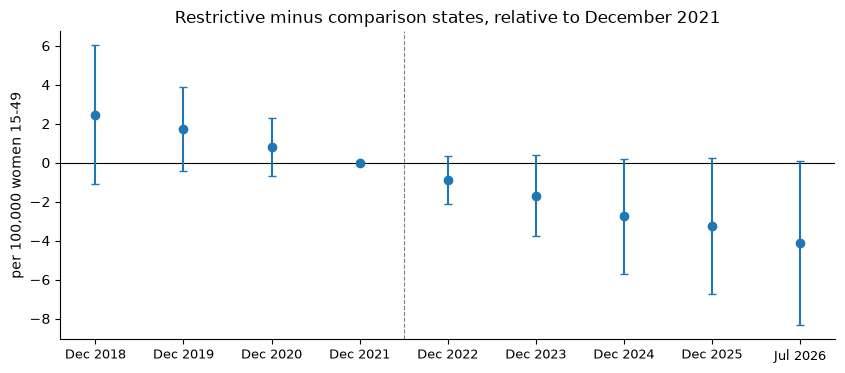

,Estimate,2.5%,97.5%,Pr(>|t|)
year,,,,
2018,2.46,-1.10,6.03,0.17
2019,1.73,-0.45,3.91,0.11
2020,0.81,-0.69,2.30,0.28
2021,0.00,0.00,0.00,NaN
2022,-0.90,-2.12,0.32,0.14
2023,-1.70,-3.77,0.38,0.10
2024,-2.75,-5.70,0.20,0.07
2025,-3.26,-6.75,0.23,0.07
2026,-4.14,-8.34,0.06,0.05


In [9]:
es = pf.feols("obgyn_rate ~ i(year, restrictive, ref=2021) | state + year", data=extended, vcov={"CRV1": "state"})
coefs = es.tidy()
coefs["year"] = coefs.index.str.extract(r"(\d{4})", expand=False).astype(int).values
coefs = pd.concat([coefs, pd.DataFrame({"Estimate": [0.0], "2.5%": [0.0], "97.5%": [0.0], "year": [2021]})]).sort_values("year")
fig, ax = plt.subplots()
ax.axhline(0, color="k", lw=0.8); ax.axvline(2022 - 0.5, color="gray", ls="--", lw=0.8)
ax.errorbar(coefs.year, coefs.Estimate, yerr=[coefs.Estimate - coefs["2.5%"], coefs["97.5%"] - coefs.Estimate], fmt="o", capsize=3)
ax.set_xticks(coefs.year); ax.set_xticklabels([f"Dec {y}" if y < 2026 else "Jul 2026" for y in coefs.year], fontsize=9)
ax.set_ylabel("per 100,000 women 15-49"); ax.set_title("Restrictive minus comparison states, relative to December 2021")
plt.show()
coefs.set_index("year")[["Estimate", "2.5%", "97.5%", "Pr(>|t|)"]].round(2)

The year-by-year estimates lie close to one straight line from 2018 to 2026. No pre-period year differs significantly from 2021, which is what the paper's test reported, but the point estimates fall by about 0.8 per 100,000 a year before *Dobbs*, and keep falling at about that pace after it.

The paper's test compares "the difference in provider supply trends between the most restrictive and comparison states in the pre-*Dobbs* period": a linear trend for the restrictive states, on top of state and year fixed effects, in the four pre-period files. Below are the same test and the estimate that a trend of that size alone, with no effect of *Dobbs* at all, would produce in each panel (the slope times the distance in years between the mean post-period and the mean pre-period file).

In [10]:
pre = paper[paper.post == 0].assign(trend=lambda d: d.year - 2018)
trend = pf.feols("obgyn_rate ~ restrictive:trend | state + year", data=pre, vcov={"CRV1": "state"}).tidy().iloc[0]
print("pre-period differential trend: {:.2f} per 100,000 a year (95% CI {:.2f} to {:.2f}, P = {:.2f})".format(
    trend["Estimate"], trend["2.5%"], trend["97.5%"], trend["Pr(>|t|)"]))
years = lambda d: (pd.to_datetime(d.as_of_date) - pd.Timestamp("2018-12-01")).dt.days / 365.25   # July files are half a year on
pd.DataFrame({name: {"estimated": did(d)["estimate"],
                     "trend alone": trend["Estimate"] * (years(d[d.post == 1]).mean() - years(d[d.post == 0]).mean())}
              for name, d in (("paper's years", paper), ("extended", extended))}).T.round(2)

pre-period differential trend: -0.83 per 100,000 a year (95% CI -1.99 to 0.33, P = 0.15)


,estimated,trend alone
paper's years,-3.17,-2.78
extended,-3.80,-3.66


The pre-period trend is not significant, so the test does not reject parallel trends; with 26 states and four pre-period files it has little power. But continued at its point estimate, the pre-*Dobbs* divergence alone accounts for most of the paper's estimate and nearly all of the extended one.

The December files are twelve points on a monthly series. Below are the mean state rate in each group, every month from January 2018, and the linear slope of the gap before and after the decision.

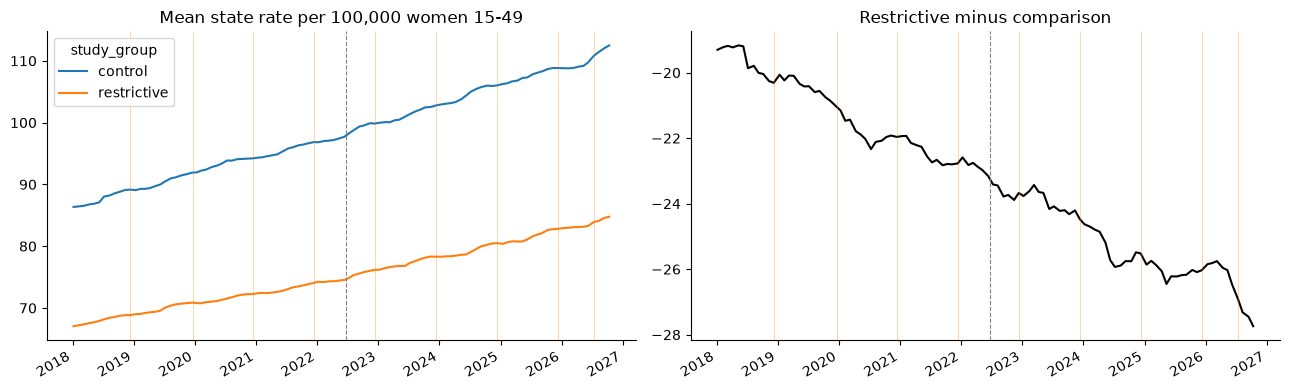

months: 106 from 2018-01-07 to 2026-10-11
slope of the gap before Dobbs: -0.93 per 100,000 a year
slope of the gap after Dobbs: -0.87 per 100,000 a year


study_group,control,restrictive,gap
as_of_date,,,
2018-01-07,86.4,67.1,-19.3
2022-06-12,97.7,74.5,-23.2
2026-10-11,112.5,84.8,-27.7


In [11]:
con.execute("""
CREATE TABLE monthly AS
SELECT n.as_of_date, s.state, s.study_group, s.women,
       count(v.npi) FILTER (WHERE v.obgyn) AS obgyn
FROM snapshots n
CROSS JOIN states s
LEFT JOIN study_versions v ON v.state = s.state AND v.effective_date <= n.as_of_date
                          AND (v.end_date IS NULL OR v.end_date > n.as_of_date)
WHERE s.study_group IS NOT NULL AND n.as_of_date >= DATE '2018-01-01'
GROUP BY ALL;
""")
monthly = con.table("monthly").df()
monthly["rate"] = monthly.obgyn / monthly.women * 1e5
series = monthly.groupby(["as_of_date", "study_group"]).rate.mean().unstack()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
series.plot(ax=axes[0]); axes[0].set_title("Mean state rate per 100,000 women 15-49"); axes[0].set_xlabel("")
(series.restrictive - series.control).plot(ax=axes[1], color="k"); axes[1].set_title("Restrictive minus comparison"); axes[1].set_xlabel("")
for ax in axes:
    ax.axvline(pd.Timestamp("2022-06-24"), color="gray", ls="--", lw=0.8)
    for d in sorted(set(extended.as_of_date)):
        ax.axvline(pd.Timestamp(d), color="tab:orange", lw=0.4, alpha=0.6)
plt.tight_layout(); plt.show()
print("months:", len(series), "from", series.index.min().date(), "to", series.index.max().date())
gap = (series.restrictive - series.control).rename("gap").reset_index()
gap["years"] = (gap.as_of_date - gap.as_of_date.min()).dt.days / 365.25
dobbs = gap.as_of_date >= pd.Timestamp("2022-06-24")
for label, part in (("before Dobbs", gap[~dobbs]), ("after Dobbs", gap[dobbs])):
    print(f"slope of the gap {label}: {np.polyfit(part.years, part.gap, 1)[0]:.2f} per 100,000 a year")
series[series.index.strftime("%Y-%m").isin(["2018-01", "2022-06", "2026-10"])].assign(gap=lambda d: d.restrictive - d.control).round(1)

Both groups' rates rise through the whole period, the comparison states' from 86 to 113 per 100,000 and the restrictive states' from 67 to 85, and the gap between them widens steadily, from 19.3 to 27.7. Its slope is -0.93 per 100,000 a year before *Dobbs* and -0.87 after. The monthly series has no break in June 2022 or in the months after it, where a response to the bans, or a delayed NPPES update of one, would show.

## 6. Reading the results

The paper's numbers reproduce from public data to within a few tenths per 100,000, and so do its two sample sensitivity checks. Two more years of files make its estimate larger, not smaller. But the restrictive states were falling behind the comparison states at the same pace before the decision as after it, and the paper's own parallel-trends test, while not significant, puts the pre-*Dobbs* divergence at about the size of the effect. The data are consistent with the estimate being that divergence continued, and they do not show a change at *Dobbs*. They cannot rule out an effect of the bans that happens to replace an earlier cause of the same size; four years of monthly files do not separate the two.

## 7. What to be careful about

* **A count of NPI records, not of clinicians at work.** NPPES has the practice address the clinician last reported. A practitioner who moves, retires or stops delivering care is counted where the record says until it is updated or deactivated. The paper names this ("NPPES data, which can be delayed"); four years of follow-up shorten the lag relative to the window but do not remove it.
* **One address per practitioner.** Clinicians who practise in two states count once, in their primary state; the `practice_location` table has the secondary addresses since 2018.
* **Fixed denominators.** The rate uses the 2017-2021 population in every year, as the paper does. States whose population of women 15-49 grew faster after 2021 (Texas, Florida, Idaho, Utah) have rates that overstate their supply per resident in the later years, and the reverse where it shrank.
* **The comparison group is the paper's.** It is 14 states with pre-*Dobbs* restrictions, not every state without a ban. A published letter (Staiger, Strasser and Myers, *JAMA Intern Med* 185(9), 2025) questions this choice of counterfactual; the authors' reply reports similar results with other groupings. We have not been able to read either beyond its first paragraph, and the notebook does not try other groupings.
* **Nurse practitioner codes are ours.** eTable 1 lists none, so the family physician and nurse practitioner sensitivity sample is the paper's design with our reading of "related to obstetrics".

## 8. Where a researcher would go next

* Read the Staiger, Strasser and Myers letter and rerun section 4 with the comparison groups it and the reply discuss.
* Strasser, Schenk, Luo and Chen (*Health Affairs Scholar* 2(12), 2024) study the same question with Medicare enrollment records and find no significant change in the two years after *Dobbs*. The public Medicare Fee-For-Service Provider Enrollment files are a second, independent source for the same states and years.
* Update the denominators each year with the ACS 1-year estimates.
* Designs that allow for the pre-*Dobbs* divergence (state-specific trends, synthetic controls) are the obvious next step; they are not in the paper and are not run here.